In [23]:
import numpy as np
from nnfs.datasets import spiral_data
import nnfs
nnfs.init()
import matplotlib.pyplot as plt

In [24]:
# this what we have so far - full numpy implementation of all layers, with forward and backward
# Linear Layer
class Layer_Dense:
    # Layer initialization
    def __init__(self, n_inputs, n_neurons):
        # Initialize weights and biases
        self.weights = np.random.randn(n_inputs, n_neurons) * (n_inputs)**-0.5
        self.biases = np.zeros((1, n_neurons))

    # Forward pass
    def forward(self, inputs):
        # Remember input values
        self.inputs = inputs
        # Calculate output values from input ones, weights and biases
        self.output = np.dot(inputs, self.weights) + self.biases

    # Backward pass
    def backward(self, dvalues):
        # Gradients on parameters
        self.dweights = np.dot(self.inputs.T, dvalues)
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
        # Gradient on values
        self.dinputs = np.dot(dvalues, self.weights.T)

# ReLU activation
class Activation_ReLU:
    # Forward pass
    def forward(self, inputs):
        # Remember input values
        self.inputs = inputs
        # Calculate output values from inputs
        self.output = np.maximum(0, inputs)

    # Backward pass
    def backward(self, dvalues):
        # Since we need to modify the original variable,
        # let’s make a copy of values first
        self.dinputs = dvalues.copy()
        # Zero gradient where input values were negative
        self.dinputs[self.inputs <= 0] = 0

# Softmax activation
class Activation_Softmax:
 # Forward pass
    def forward(self, inputs):
        # Get unnormalized probabilities
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True)) # recall we subtract the max, since extreme logits will result in inf/nan softmaxes, small values are much more stable
        # Normalize them for each sample
        probabilities = exp_values / np.sum(exp_values, axis=1,keepdims=True)
        self.output = probabilities

  # Common loss class
class Loss:
    # Calculates the data and regularization losses
    # given model output and ground truth values
    def calculate(self, output, y):
        # Calculate sample losses
        sample_losses = self.forward(output, y)
        # Calculate mean loss
        data_loss = np.mean(sample_losses)
        # Return loss
        return data_loss


class Loss_CategoricalCrossentropy(Loss):
    # Forward pass
    def forward(self, y_pred, y_true):
        # Number of samples in a batch
        samples = len(y_pred)

        # Clip data to prevent division by 0
        # Clip both sides to not drag mean towards any value
        y_pred_clipped = np.clip(y_pred, 1e-7, 1 - 1e-7)

        # Probabilities for target values -
        # only if categorical labels
        if len(y_true.shape) == 1:
            correct_confidences = y_pred_clipped[
                range(samples),
                y_true
            ]
        # Mask values - only for one-hot encoded labels
        elif len(y_true.shape) == 2:
            correct_confidences = np.sum(
                y_pred_clipped * y_true,
                axis=1
            )

        # Losses
        negative_log_likelihoods = -np.log(correct_confidences)
        return negative_log_likelihoods

    # Backward pass
    def backward(self, dvalues, y_true):
        # Number of samples
        samples = len(dvalues)
        # Number of labels in every sample
        # We'll use the first sample to count them
        labels = len(dvalues[0])

        # If labels are sparse, turn them into one-hot vector
        if len(y_true.shape) == 1:
            y_true = np.eye(labels)[y_true]

        # Calculate gradient
        self.dinputs = -y_true / dvalues
        # Normalize gradient
        self.dinputs = self.dinputs / samples

# Softmax classifier - combined Softmax activation
# and cross-entropy loss for faster backward step
class Activation_Softmax_Loss_CategoricalCrossentropy:
    # Creates activation and loss function objects
    def __init__(self):
        self.activation = Activation_Softmax()
        self.loss = Loss_CategoricalCrossentropy()

    # Forward pass
    def forward(self, inputs, y_true):
        # Output layer's activation function
        self.activation.forward(inputs)
        # Set the output
        self.output = self.activation.output
        # Calculate and return loss value
        return self.loss.calculate(self.output, y_true)

    # Backward pass
    def backward(self, dvalues, y_true):
        # Number of samples
        samples = len(dvalues)
        # If labels are one-hot encoded,
        # turn them into discrete values
        if len(y_true.shape) == 2:
            y_true = np.argmax(y_true, axis=1)
        # Copy so we can safely modify
        self.dinputs = dvalues.copy()
        # Calculate gradient
        self.dinputs[range(samples), y_true] -= 1
        # Normalize gradient
        self.dinputs = self.dinputs / samples


In [25]:
# SGD optimizer

# this includes a decay, which shrinks the learning rate in proportion to the training iterations, with this scale being controlled by some arbitrary decay parameter usually (1e-3 etc)
# by decaying the learning rate, the loss is less likely to bounce around or become unstable throughout training, but can optimise quickly at the start
class Optimizer_SGD:
    # Initialize optimizer - set settings,
    # learning rate of 1. is default for this optimizer
    def __init__(self, learning_rate=1., decay=0.):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
            (1. / (1. + self.decay * self.iterations))
    # Update parameters
    def update_params(self, layer):
        layer.weights += -self.current_learning_rate * layer.dweights
        layer.biases += -self.current_learning_rate * layer.dbiases
    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1



In [26]:
# Momentum optimiser
# momentum can reduce oscillations or instability during gradient descent, by including information on the previous gradient descent steps
# momentum gradient descent formula:
# new param value = old param value             
#                   - (lr * gradient)                  we still apply a normal gradient descent step
#                   + momentum_factor * previous weight updates             but we just add on information about the past, scaled by momentum_factor (usually 0.9)

# previous weight updates is probably a list of all of the nudges that were made to those parameters throughout training so far
# so we would recursively append -(lr * gradient) + (momentum_factor * previous weight updates) to the previous weight updates list

# note, we often use a decayed lr with momentum as well
# so 3 parameters all up: initial learning rate, decay, and momentum factor

# we will build on the original SGD class since the learning rate and decay remain unchanged

class Optimizer_Momentum:
    # Initialize optimizer - set settings,
    # learning rate of 1. is default for this optimizer
    def __init__(self, learning_rate=1., decay=1e-4, momentum=0.9):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.momentum = momentum

    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
            (1. / (1. + self.decay * self.iterations))


    # Update parameters
    def update_params(self, layer):

        # intialise momentums with 0, in the same shape so broadcasting works
        if not hasattr(layer, 'weight_momentums'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)

        # create the nudge for this step, regular SGD with scaled momentum value
        weight_update = -self.current_learning_rate * layer.dweights + self.momentum * layer.weight_momentums
        bias_update = -self.current_learning_rate * layer.dbiases + self.momentum * layer.bias_momentums

        # do the nudge
        layer.weights += weight_update
        layer.biases += bias_update

        # update the momentum with that nudge (check if this is += or just = )
        layer.weight_momentums = weight_update
        layer.bias_momentums = bias_update


    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1


In [27]:
# AdaGrad - Adaptive gradient (note adagrad doesnt get used much in practice, but is a good first step in learning the Adam optimiser which is a commonly used one)
# this has a different learning rate for each parameter, rather than the global learning rate seen in regular SGD and momentum
# this is designed to handle the differing values that the weights and their gradients can take - some gradients will be exponentially larger than others, 
# and with the same learning rate this means some nudges will be exponentially larger than others 
# in some cases this can lead to non-convergence or instability with some weights blowing up and bouncing around while some would barely train

# ideally we want our learning rates to normalise the nudges:
# - the higher the parameter gradient, the smaller the associated learning rate
# - the lower the parameter gradient, the higher the associated learning rate

# algorithm is:
# for every parameter, store a history of gradients: cache = cache + gradient^2
# then, the update is learning_rate * gradient / sqrt(cache + epsilon) 

# some notes:
# - learning rate is as we have seem before, usually implemented with decay
# - we square the gradient in the cache so the steps dont randomly change direction
# - cache in the denominator implements the normalisation
# - epsilon is a small number to handle possible division by 0


# issues - over many training iterations, the cache value can grow disproportionately large, which means our param updates converge to 0, and the model may stop training
# build on the SGD with decay

class Optimizer_ADAGrad:

    def __init__(self, learning_rate=1., decay=1e-4, epsilon=1e-7):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
            (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        if not hasattr(layer, 'weights_cache'):
            layer.weights_cache = np.zeros_like(layer.weights)
            layer.biases_cache = np.zeros_like(layer.biases)

        layer.weights_cache += (layer.dweights)**2
        layer.biases_cache += (layer.dbiases)**2

        weights_update = (-self.current_learning_rate*layer.dweights)/(np.sqrt(layer.weights_cache) + self.epsilon) # test epsilon in or out of sqrt
        biases_update = (-self.current_learning_rate*layer.dbiases)/(np.sqrt(layer.biases_cache) + self.epsilon)
        
        layer.weights += weights_update
        layer.biases += biases_update



    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

In [28]:
# RMSProp - root mean square propagation

# very similar to adagrad, but it aims to solve the problem of the cache blowing out and causing our updates to converge to 0
# it does this by adding a tuning parameter rho (0-1), which controls how much the latest/present gradient impacts the cache i.e. past gradients
# higher rho means cache updates/grows slower and more stably, lower means cache more reactive to latest parameter gradient
# with a high rho, this means the cache will stay very close to 0 at the start of training, meaning the actual nudge will blow up and training will be instantly unstable 
# if the initial learning rate isn't scaled accordingly - drop it down to 0.01 or so


# difference between momentum and adagrad/rms
# momentum will add the same learning rate nudge, and then a little extra in the direction each parameter was already going (literally momentum)
# adagrad/rms scale the learning rate nudge by the size of the steps it has been taking (regardless of direction) for each parameter



# build on adagrad
class Optimizer_RMSProp:

    def __init__(self, learning_rate=0.1, decay=1e-4, epsilon=1e-7, rho=0.9):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.rho = rho

    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
            (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        if not hasattr(layer, 'weights_cache'):
            layer.weights_cache = np.zeros_like(layer.weights)
            layer.biases_cache = np.zeros_like(layer.biases)

        # only difference from above is here
        layer.weights_cache = self.rho * layer.weights_cache + (1-self.rho) * layer.dweights**2
        layer.biases_cache = self.rho * layer.biases_cache + (1-self.rho) * layer.dbiases**2

        weights_update = (-self.current_learning_rate*layer.dweights)/np.sqrt(layer.weights_cache + self.epsilon) # test epsilon in or out of sqrt
        biases_update = (-self.current_learning_rate*layer.dbiases)/np.sqrt(layer.biases_cache + self.epsilon)
        
        layer.weights += weights_update
        layer.biases += biases_update



    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

In [29]:
# ADAM Optimiser

# basically a combination of RMSProp and Momentum
# so we add the momentum of past step changes, and scale them for each parameter based on size of those changes
# recall the rmsprop formula weight += -lr * grad / sqrt(cache + epsilon)
# here we replace the lone grad with the momentum adjusted gradient (b * momentum + (1 - b) * grad)

# some notes:
# since we initialise cache and momentum as 0, in early iterations they can cause our step size to be very small and its easy to get stuck.
# therefore, we divide both by (1-b ^ t) where t is the iteration num: starts out as 1, so for b=0.9, (1-b^t) = 0.1, so dividing by this scales up both our momentum and cache
# conversely as t gets larger, since b < 1, 1-b just approaches 1 so the scaling effect disappears

# final adam formula

'''
param += -lr * (momentum / (1-b1^t))   /    sqrt( cache / (1-b2^t) + epsilon)

'''
# generally set b1 and b2 to ~ 0.9


class Optimizer_Adam:

    def __init__(self, learning_rate=0.1, decay=1e-4, epsilon=1e-7, beta1 = 0.9, beta2 = 0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta1
        self.beta_2 = beta2

    # Call once before any parameter updates
    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * \
            (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays,
        # create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)
            
        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass
        # and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization
        # with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / \
        (np.sqrt(weight_cache_corrected) + self.epsilon)

        layer.biases += -self.current_learning_rate * bias_momentums_corrected / \
        (np.sqrt(bias_cache_corrected) + self.epsilon)



    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

In [30]:
# Create dataset
np.random.seed(42)
X, y = spiral_data(samples=100, classes=3)

In [31]:
# quick note on loss vs accuracy
# even if loss decreases, that doesn't mean that our accuracy improves
# consider an example that the model is correctly predicting as class 1 with 0.34 softmax probability (greatest out of the 3 logits) - over the course of training this probability keeps increasing to 0.99
# the mean loss contribution for this example will go from -ln(0.34) to -ln(0.99), but the accuracy remains unchanged
# similarly, consider an example that the model was correctly predicting as class 1 with 0.34 softmax probability, but over the course of training this probability drops to 0.32 and is no longer the greatest softmax probability
# the change in mean loss contribution would be negligible, but the accuracy is notably affected

In [54]:
# Initialise and training step

np.random.seed(43)
iterations = 5001
batch_size = None

# Create Dense layer with 2 input features and 64 output values
dense1 = Layer_Dense(2, 64)
dense1.weights *= np.sqrt(2) # scale by the kaiming init gain for relu

# Create ReLU activation (to be used with Dense layer)
activation1 = Activation_ReLU()

# Create second Dense layer with 64 input features (as we take output
# of previous layer here) and 3 output values (output values)
dense2 = Layer_Dense(64, 3)

# Create Softmax classifier's combined loss and activation
loss_activation = Activation_Softmax_Loss_CategoricalCrossentropy()

# Create optimizer
optimizer = Optimizer_Adam(learning_rate=0.05, decay=5e-7)

losses = []

# Train in loop
for epoch in range(iterations):
    # Perform a forward pass of our training data through this layer

    # try batching
    if batch_size:            
        ix = np.random.randint(0, len(X)-1, size=batch_size)
        Xb, yb = X[ix], y[ix]
    else:
        Xb, yb = X, y

    dense1.forward(Xb)
    
    # Perform a forward pass through activation function
    # takes the output of first dense layer here
    activation1.forward(dense1.output)
    
    # Perform a forward pass through second Dense layer
    # takes outputs of activation function of first layer as inputs
    dense2.forward(activation1.output)

    # Perform a forward pass through the activation/loss function
    # takes the output of second dense layer here and returns loss
    loss = loss_activation.forward(dense2.output, yb)
    
    # Calculate accuracy from output of activation2 and targets
    # calculate values along first axis
    predictions = np.argmax(loss_activation.output, axis=1)
    if len(yb.shape) == 2:
        yb = np.argmax(yb, axis=1)
    accuracy = np.mean(predictions == yb)
    
    if not epoch % 1000:
        print(f'epoch: {epoch}, ' +
              f'acc: {accuracy:.3f}, ' +
              f'loss: {loss:.3f}, ' +
              f'lr: {optimizer.current_learning_rate}')

    losses.append(loss)

    # quick and simple lr decay - halfway through, reduce the lr by half
    # if epoch >= int(iterations/2):
    #     optimizer.learning_rate = start_learning_rate/2

    # now try proper decay
    # decay = 1/iterations
    # optimizer.learning_rate = start_learning_rate / (1 + decay * epoch)
    
    # dont need the above with our new class changes

    # Backward pass
    loss_activation.backward(loss_activation.output, yb)
    dense2.backward(loss_activation.dinputs)
    activation1.backward(dense2.dinputs)
    dense1.backward(activation1.dinputs)
    
    # Update weights and biases
    optimizer.pre_update_params() # need this now to set the new decayed learning rate
    optimizer.update_params(dense1)
    optimizer.update_params(dense2)
    optimizer.post_update_params() # need this now to track the iterations for the decayed learning rate

epoch: 0, acc: 0.317, loss: 1.182, lr: 0.05
epoch: 1000, acc: 0.953, loss: 0.100, lr: 0.049975037468784345
epoch: 2000, acc: 0.957, loss: 0.082, lr: 0.04995007490013731
epoch: 3000, acc: 0.960, loss: 0.072, lr: 0.049925137256683606
epoch: 4000, acc: 0.960, loss: 0.065, lr: 0.049900224501110035
epoch: 5000, acc: 0.963, loss: 0.064, lr: 0.04987533659617785


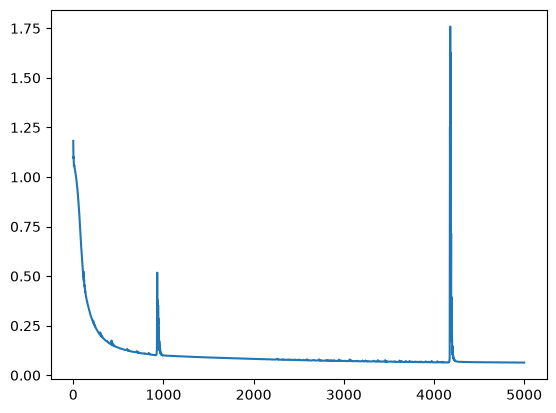

In [55]:
plt.plot(losses)

In [34]:
# document for seed 42
# 100k iterations, 0.1 lr, halve it halfway: acc: 0.713, loss: 0.700, very different loss curve tho, big divergence just before halfway
# 100k iterations with actual decay lr = 0.1/(1+ (1/iterations) * epoch): acc: 0.690, loss: 0.668: smoother loss curve throughout, tiny bit bumpy at end
# 100k iterations with actual decay lr = 0.5/(1+ (1/iterations) * epoch): 
                                                        # epoch: 99000, acc: 0.807, loss: 0.510
                                                        # epoch: 100000, acc: 0.670, loss: 0.890 fast convergence to lower value, but very unstable losses throughout

# 100k iterations with actual decay lr = 0.25/(1+ (1/iterations) * epoch): epoch: 100000, acc: 0.840, loss: 0.375, still very unstable

# 150k iterations with decay learning_rate=0.3, decay=1e-4, epoch: 150000, acc: 0.830, loss: 0.407, very stable training as well


# now adding momentum
# we need way less iterations
# 25k iterations, learning_rate=0.3, decay=1e-4, momentum=0.9, epoch: 25000, acc: 0.970, loss: 0.069, 

# adagrad
# could keep improving with more iterations, but as cache grows the updates at every step converge to 0 anyway
# 25k iterations, learning_rate=0.3, decay=1e-4, epsilon=1e-7, epoch: 25000, acc: 0.937, loss: 0.145



In [57]:
# inference

# create test data
np.random.seed(434)
X_test, y_test = spiral_data(samples=100, classes=3)


# forward pass
dense1.forward(X_test)
activation1.forward(dense1.output)
dense2.forward(activation1.output)
loss = loss_activation.forward(dense2.output, y_test)

predictions = np.argmax(loss_activation.output, axis=1)
if len(y_test.shape) == 2:
    y_test = np.argmax(y_test, axis=1)
accuracy = np.mean(predictions == y_test)


print(
        f'acc: {accuracy:.3f}, ' +
        f'loss: {loss:.3f}')

# clearly overfitting with only 0.823 accuracy

acc: 0.830, loss: 1.132
